# Cross-Environment Comparison: d' (Empathic vs Non-Empathic)

Loads episode-summary CSVs from **2D**, **Game-theoretic**, and **Graph** environments.
For each hypothesis (outcome metric), computes **d'** (sensitivity) between empathic and non-empathic distributions **per run**, then plots one **box plot per hypothesis** with one box per environment.

**Prerequisite:** Generate graph results first by running `agents_graph/main_graph.py` (with `DEFAULT_GRAPH_TYPE = 'dynamic'`). Results go to `agents_graph/graph_simulation_results_dynamic/`.

## 1. Paths and config

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths relative to repo root (run from repo root or from comparison/ folder)
ROOT = os.path.abspath(".")
if os.path.basename(ROOT) == "comparison":
    ROOT = os.path.dirname(ROOT)

FOLDER_2D = os.path.join(ROOT, "2D", "2D_simulation_results")
FOLDER_GT = os.path.join(ROOT, "empathy_tragedy", "GT_simulation_jerome_thesis_emp")
FOLDER_GRAPH = os.path.join(ROOT, "agents_graph", "graph_simulation_results_dynamic")

# Fallback to non-dynamic graph results if dynamic folder is missing
if not os.path.isdir(FOLDER_GRAPH):
    FOLDER_GRAPH = os.path.join(ROOT, "agents_graph", "graph_simulation_results")

print("2D:", FOLDER_2D, "exists:", os.path.isdir(FOLDER_2D))
print("GT:", FOLDER_GT, "exists:", os.path.isdir(FOLDER_GT))
print("Graph:", FOLDER_GRAPH, "exists:", os.path.isdir(FOLDER_GRAPH))

2D: c:\Users\evann\OneDrive\Documents\1.neuro\ISIR\2D\2D_simulation_results exists: True
GT: c:\Users\evann\OneDrive\Documents\1.neuro\ISIR\empathy_tragedy\GT_simulation_jerome_thesis_emp exists: True
Graph: c:\Users\evann\OneDrive\Documents\1.neuro\ISIR\agents_graph\graph_simulation_results_dynamic exists: True


## 2. Loaders: parse filenames and load CSVs

In [2]:
def load_2d_results(folder: str):
    """Load 2D episode_summary CSVs. Filename contains alpha (e.g. alpha0.0, alpha0.5) and simulation index (results_000_, results_001_)."""
    # e.g. results_000_300_grid5_..._alpha0.5_..._episode_summary.csv
    pattern = re.compile(r"results_(?P<sim>\d{3})_.*_alpha(?P<alpha>[\d.]+)_.*_episode_summary(?:\d*)\.csv")
    dfs = []
    for f in os.listdir(folder):
        if not f.endswith(".csv") or "aggregated" in f:
            continue
        m = pattern.match(f)
        if not m:
            continue
        path = os.path.join(folder, f)
        df = pd.read_csv(path)
        df["environment"] = "2D"
        df["alpha"] = float(m.group("alpha"))
        df["run_id"] = int(m.group("sim"))
        df["filename"] = f
        dfs.append(df)
    if not dfs:
        return pd.DataFrame()
    return pd.concat(dfs, ignore_index=True)


def load_gt_results(folder: str):
    """Load game-theoretic episode_summary CSVs. Alpha is in filename (e.g. 0.5 or 0 after True)."""
    # e.g. results_000_50_DQN_average_True_0.5_0.5_linear_... -> alpha=0.5 (first 0.5 after True)
    pattern = re.compile(r"results_(?P<sim>\d{3})_\d+_DQN_[^_]+_True_(?P<alpha>[\d.]+)_.*episode_summary\d*\.csv")
    dfs = []
    for f in os.listdir(folder):
        if not f.endswith(".csv"):
            continue
        m = pattern.match(f)
        if not m:
            continue
        path = os.path.join(folder, f)
        df = pd.read_csv(path)
        df["environment"] = "Game-theoretic"
        df["alpha"] = float(m.group("alpha"))
        df["run_id"] = int(m.group("sim"))
        df["filename"] = f
        # Reconstruct depletion step as last step reached in each episode (GT has no explicit depletion_step)
        df["depletion_step"] = df["total_steps"]
        dfs.append(df)
    if not dfs:
        return pd.DataFrame()
    return pd.concat(dfs, ignore_index=True)


def load_graph_results(folder: str):
    """Load graph episode_summary CSVs. Filename: graph_results_000_..._graphdynamic_alpha0.5_..."""
    pattern = re.compile(r"graph_results_(?P<sim>\d{3})_.*_graph\w+_alpha(?P<alpha>[\d.]+)_.*_episode_summary\d*\.csv")
    dfs = []
    for f in os.listdir(folder):
        if not f.endswith(".csv"):
            continue
        m = pattern.match(f)
        if not m:
            continue
        path = os.path.join(folder, f)
        df = pd.read_csv(path)
        df["environment"] = "Graph"
        df["alpha"] = float(m.group("alpha"))
        df["run_id"] = int(m.group("sim"))
        df["filename"] = f
        dfs.append(df)
    if not dfs:
        return pd.DataFrame()
    return pd.concat(dfs, ignore_index=True)


df_2d = load_2d_results(FOLDER_2D)
df_gt = load_gt_results(FOLDER_GT)
df_graph = load_graph_results(FOLDER_GRAPH)

print("2D rows:", len(df_2d), "runs:", df_2d["run_id"].nunique() if len(df_2d) else 0, "alphas:", sorted(df_2d["alpha"].unique().tolist()) if len(df_2d) else [])
print("GT rows:", len(df_gt), "runs:", df_gt["run_id"].nunique() if len(df_gt) else 0, "alphas:", sorted(df_gt["alpha"].unique().tolist()) if len(df_gt) else [])
print("Graph rows:", len(df_graph), "runs:", df_graph["run_id"].nunique() if len(df_graph) else 0, "alphas:", sorted(df_graph["alpha"].unique().tolist()) if len(df_graph) else [])

2D rows: 2399 runs: 3 alphas: [0.0, 0.5]
GT rows: 1600 runs: 4 alphas: [0.0, 0.5]
Graph rows: 1800 runs: 3 alphas: [0.0, 0.5]


In [3]:
# Build unified frame for metrics that exist in all loaded envs (optional: combine for inspection)
all_dfs = []
if len(df_2d):
    all_dfs.append(df_2d)
if len(df_gt):
    all_dfs.append(df_gt)
if len(df_graph):
    all_dfs.append(df_graph)

if all_dfs:
    combined = pd.concat(all_dfs, ignore_index=True)
    print("Combined columns (sample):", [c for c in combined.columns[:20]])
else:
    combined = pd.DataFrame()

Combined columns (sample): ['simulation_number', 'seed', 'episode', 'total_steps', 'resources_remaining', 'depletion_step', 'avg_resources_during_episode', 'gini_consumption', 'gini_satisfaction', 'avg_inter_agent_distance', 'empathic_penalties_count', 'total_consumption', 'total_reward_0', 'total_reward_1', 'total_reward_2', 'total_reward_3', 'total_reward_4', 'total_exploits_0', 'total_exploits_1', 'total_exploits_2']


## 3. Metric mapping and derived columns

In [4]:
# Hypothesis name -> (column name or callable for 2D, GT, Graph). None = not available.
HYPOTHESES = {
    "Depletion step": {
        "2D": "depletion_step",
        "Game-theoretic": "depletion_step",  # reconstructed in loader as last step reached (total_steps)
        "Graph": "depletion_step",
    },
    "Gini (consumption)": {
        "2D": "gini_consumption",
        "Game-theoretic": None,
        "Graph": "gini_consumption",
    },
    "Gini (satisfaction)": {
        "2D": "gini_satisfaction",
        "Game-theoretic": None,
        "Graph": "gini_satisfaction",
    },
    "Total consumption": {
        "2D": "total_consumption",
        "Game-theoretic": None,  # can derive from rewards if needed
        "Graph": "total_consumption",
    },
    "Mean reward": {
        "2D": "mean_reward",  # derived
        "Game-theoretic": "mean_reward",  # derived from total_combined_reward_*
        "Graph": "mean_reward",  # derived
    },
    "Total steps": {
        "2D": "total_steps",
        "Game-theoretic": "total_steps",
        "Graph": "total_steps",
    },
    "Empathic penalty events": {
        "2D": "empathic_penalties_count",
        "Game-theoretic": None,
        "Graph": "empathic_penalties_count",
    },
}


def ensure_mean_reward(df: pd.DataFrame, env_name: str) -> pd.DataFrame:
    """Add mean_reward column: mean of total_reward_* or total_combined_reward_*."""
    if "mean_reward" in df.columns:
        return df
    reward_cols = [c for c in df.columns if c.startswith("total_reward_") or c.startswith("total_combined_reward_")]
    if reward_cols:
        df = df.copy()
        df["mean_reward"] = df[reward_cols].mean(axis=1)
    return df


df_2d = ensure_mean_reward(df_2d, "2D")
df_gt = ensure_mean_reward(df_gt, "Game-theoretic")
df_graph = ensure_mean_reward(df_graph, "Graph")

## 4. d' (sensitivity) and per-run d'

In [5]:
def d_prime(series_empathic: pd.Series, series_non_empathic: pd.Series, eps: float = 1e-8) -> float:
    """
    d' = (mean_empathic - mean_non_empathic) / sqrt(0.5 * (var_empathic + var_non_empathic))
    Returns float; use eps to avoid division by zero.
    """
    m1, m2 = series_empathic.mean(), series_non_empathic.mean()
    v1, v2 = series_empathic.var(ddof=1), series_non_empathic.var(ddof=1)
    if pd.isna(v1):
        v1 = 0.0
    if pd.isna(v2):
        v2 = 0.0
    pooled_std = np.sqrt(0.5 * (v1 + v2) + eps)
    if pooled_std <= 0:
        return 0.0
    return float((m1 - m2) / pooled_std)


def compute_dprime_per_run(df: pd.DataFrame, env_name: str, metric_col: str) -> list:
    """
    For one environment and one metric, group by run_id; for each run pair (empathic run r, non-empathic run r),
    compute one d'. Returns list of d' values (one per run index that has both conditions).
    """
    if df.empty or metric_col not in df.columns:
        return []
    env_df = df[df["environment"] == env_name].copy()
    if env_df.empty:
        return []
    run_ids = sorted(env_df["run_id"].unique())
    dprimes = []
    for r in run_ids:
        emp = env_df[(env_df["run_id"] == r) & (env_df["alpha"] == 0.5)][metric_col].dropna()
        ne = env_df[(env_df["run_id"] == r) & (env_df["alpha"] == 0.0)][metric_col].dropna()
        if len(emp) < 2 or len(ne) < 2:
            continue
        dprimes.append(d_prime(emp, ne))
    return dprimes


# If run_id pairing is not aligned (e.g. different run indices per condition), pair by run index position
def compute_dprime_per_run_paired(df: pd.DataFrame, env_name: str, metric_col: str) -> list:
    """
    Get all run_ids that have both alpha=0 and alpha=0.5. For each such run_id, compute d'.
    If conditions are in separate files (different run_ids), pair by simulation index 0 with 0, 1 with 1, etc.
    """
    if df.empty or metric_col not in df.columns:
        return []
    env_df = df[df["environment"] == env_name].copy()
    if env_df.empty:
        return []
    empathic_runs = sorted(env_df[env_df["alpha"] == 0.5]["run_id"].unique())
    non_empathic_runs = sorted(env_df[env_df["alpha"] == 0.0]["run_id"].unique())
    if not empathic_runs or not non_empathic_runs:
        return []
    dprimes = []
    for i in range(min(len(empathic_runs), len(non_empathic_runs))):
        emp = env_df[(env_df["run_id"] == empathic_runs[i]) & (env_df["alpha"] == 0.5)][metric_col].dropna()
        ne = env_df[(env_df["run_id"] == non_empathic_runs[i]) & (env_df["alpha"] == 0.0)][metric_col].dropna()
        if len(emp) < 2 or len(ne) < 2:
            continue
        dprimes.append(d_prime(emp, ne))
    return dprimes

In [6]:
# Build combined df for per-run d' (all envs in one frame)
combined = pd.concat([df_2d, df_gt, df_graph], ignore_index=True) if len(df_2d) or len(df_gt) or len(df_graph) else pd.DataFrame()

# Collect d' per (hypothesis, environment)
results = []  # list of (hypothesis, environment, d' value) per run -> then we need list of d' per (hypothesis, env)
plot_data = []  # list of dict: hypothesis, environment, dprime (one row per run)

for hyp_name, cols in HYPOTHESES.items():
    for env_name, col in cols.items():
        if col is None:
            continue
        dprimes = compute_dprime_per_run_paired(combined, env_name, col)
        for dp in dprimes:
            plot_data.append({"hypothesis": hyp_name, "environment": env_name, "d_prime": dp})

df_plot = pd.DataFrame(plot_data)
print(df_plot.head(20))

             hypothesis     environment   d_prime
0        Depletion step              2D  1.359392
1        Depletion step              2D -0.085764
2        Depletion step              2D  2.381253
3        Depletion step  Game-theoretic  0.122249
4        Depletion step  Game-theoretic  0.255977
5        Depletion step  Game-theoretic  0.007614
6        Depletion step  Game-theoretic  0.134900
7        Depletion step           Graph  0.000000
8        Depletion step           Graph  0.000000
9        Depletion step           Graph  0.000000
10   Gini (consumption)              2D -0.218204
11   Gini (consumption)              2D  0.289571
12   Gini (consumption)              2D  0.445780
13   Gini (consumption)           Graph  0.035846
14   Gini (consumption)           Graph  0.085696
15   Gini (consumption)           Graph  0.085880
16  Gini (satisfaction)              2D -1.438172
17  Gini (satisfaction)              2D -0.067290
18  Gini (satisfaction)              2D -1.784584


## 5. Box plots: one per hypothesis

C:\Users\evann\AppData\Local\Temp\ipykernel_42876\498744080.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=envs)
C:\Users\evann\AppData\Local\Temp\ipykernel_42876\498744080.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=envs)
C:\Users\evann\AppData\Local\Temp\ipykernel_42876\498744080.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=envs)
C:\Users\evann\AppData\Local\Temp\ipykernel_42876\498744080.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support fo

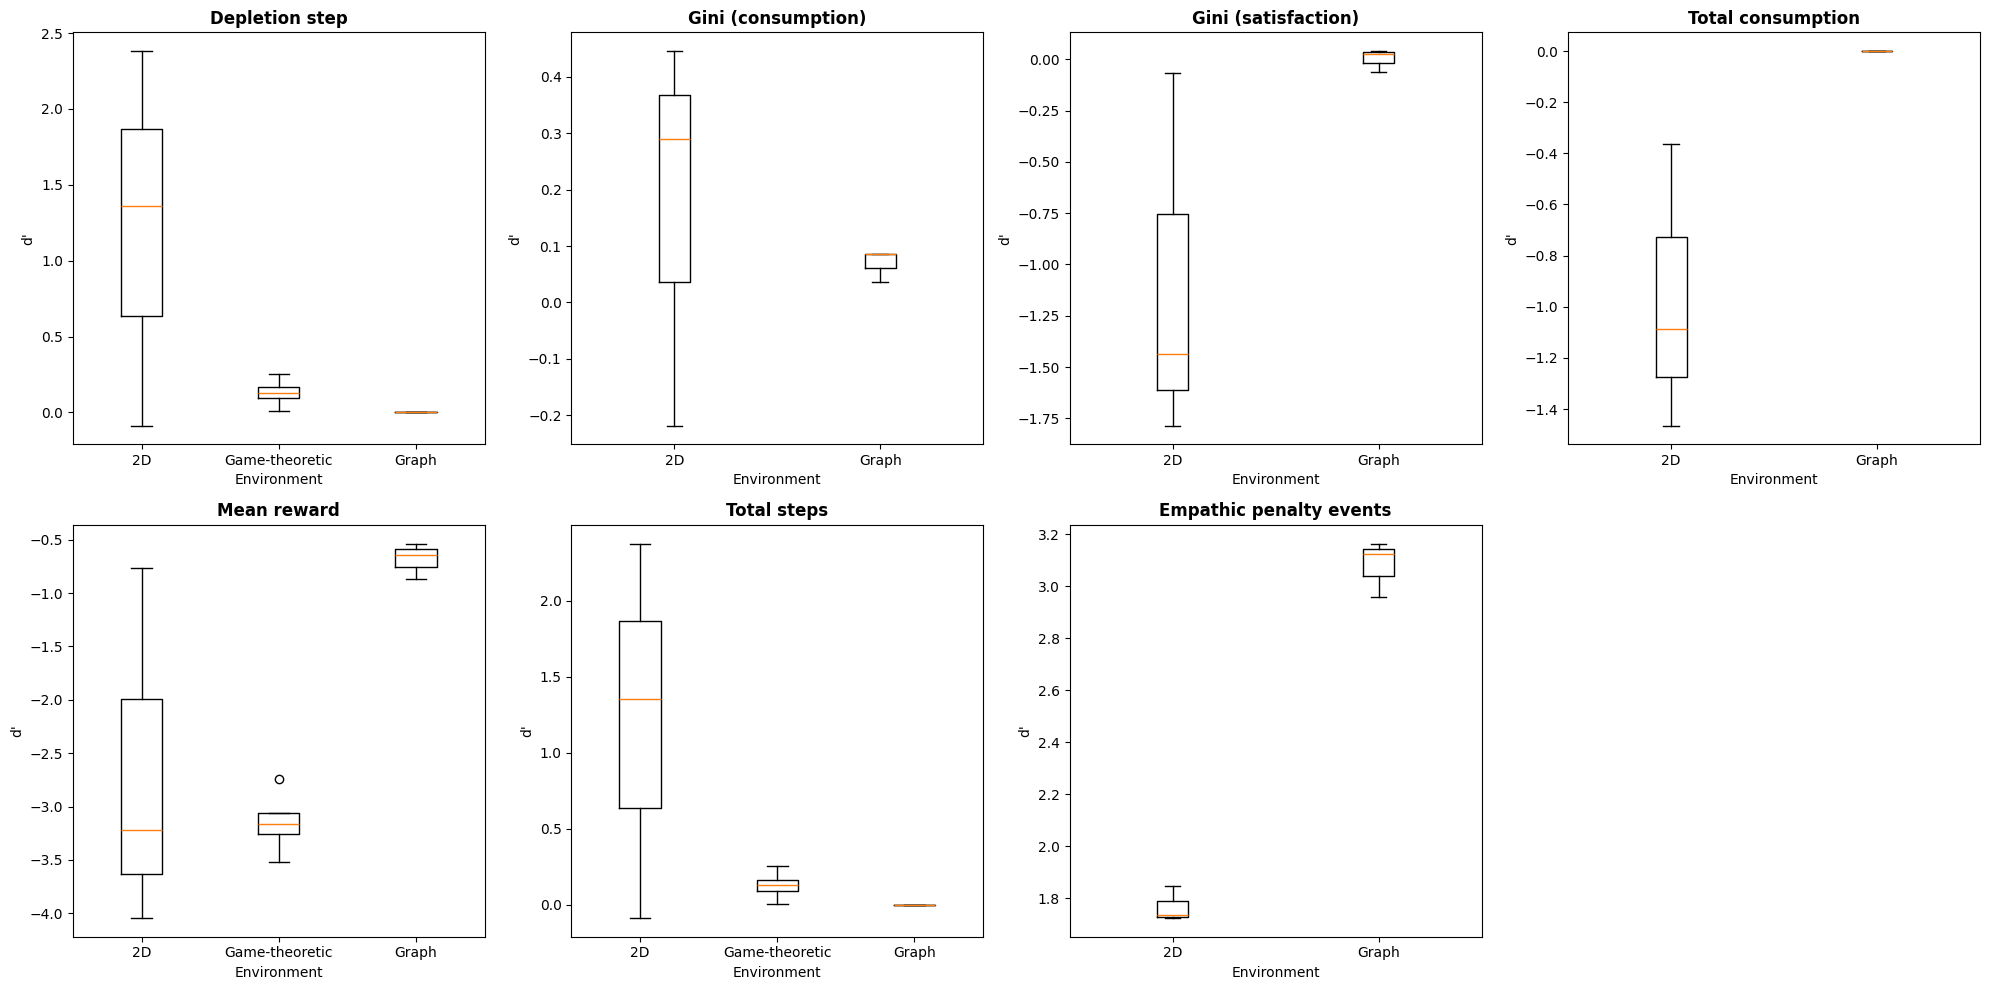

In [7]:
if df_plot.empty:
    print("No d' data to plot. Ensure 2D, GT, and/or Graph result folders contain episode_summary CSVs with both alpha=0 and alpha=0.5.")
else:
    hypotheses = df_plot["hypothesis"].unique().tolist()
    n_hyp = len(hypotheses)
    n_cols = (n_hyp + 1) // 2
    fig, axes = plt.subplots(2, max(1, n_cols), figsize=(5 * max(1, n_cols), 5 * 2))
    if n_hyp == 1:
        axes = np.array([axes])
    axes = np.atleast_2d(axes)
    axes = axes.flatten()
    for idx, hyp in enumerate(hypotheses):
        ax = axes[idx]
        sub = df_plot[df_plot["hypothesis"] == hyp]
        envs = sub["environment"].unique().tolist()
        data = [sub[sub["environment"] == e]["d_prime"].values for e in envs]
        ax.boxplot(data, labels=envs)
        ax.set_title(hyp, fontweight="bold")
        ax.set_ylabel("d'")
        ax.set_xlabel("Environment")
    for j in range(len(hypotheses), len(axes)):
        axes[j].set_visible(False)
    plt.tight_layout()
    plt.show()

C:\Users\evann\AppData\Local\Temp\ipykernel_42876\3872211883.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=envs)


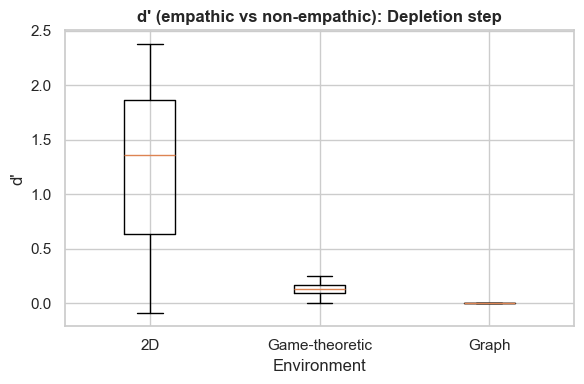

C:\Users\evann\AppData\Local\Temp\ipykernel_42876\3872211883.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=envs)


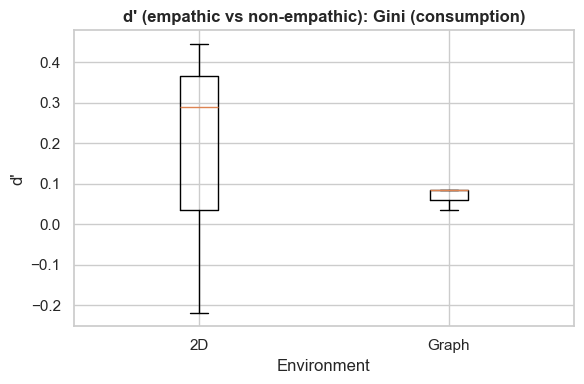

C:\Users\evann\AppData\Local\Temp\ipykernel_42876\3872211883.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=envs)


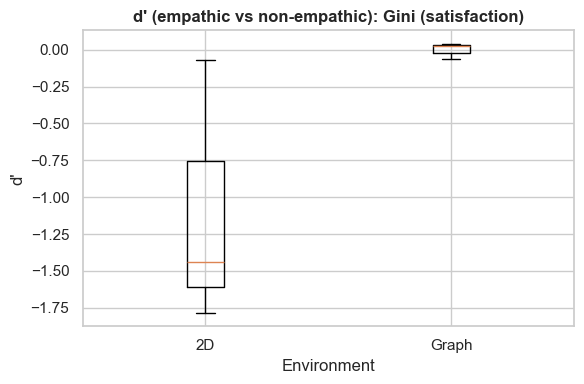

C:\Users\evann\AppData\Local\Temp\ipykernel_42876\3872211883.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=envs)


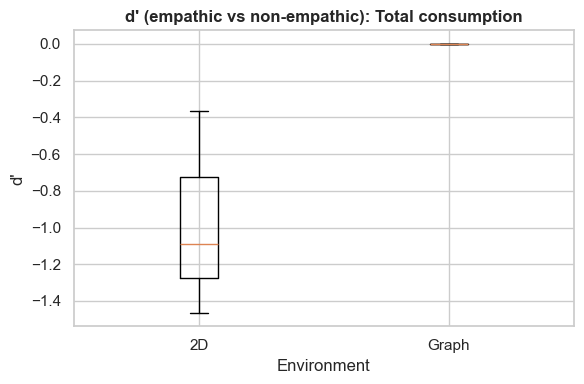

C:\Users\evann\AppData\Local\Temp\ipykernel_42876\3872211883.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=envs)


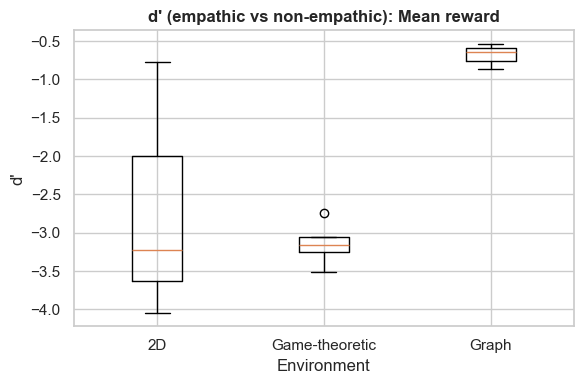

C:\Users\evann\AppData\Local\Temp\ipykernel_42876\3872211883.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=envs)


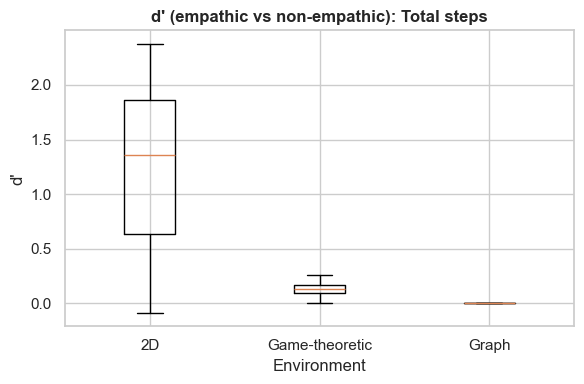

C:\Users\evann\AppData\Local\Temp\ipykernel_42876\3872211883.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=envs)


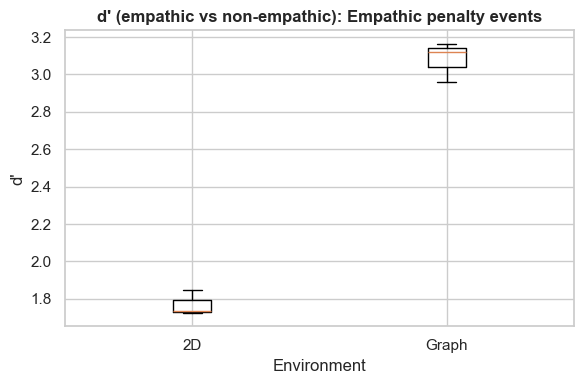

In [8]:
# Alternative: one figure per hypothesis with seaborn style
try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
except Exception:
    pass

if not df_plot.empty:
    for hyp in df_plot["hypothesis"].unique():
        sub = df_plot[df_plot["hypothesis"] == hyp]
        envs = sub["environment"].unique().tolist()
        data = [sub[sub["environment"] == e]["d_prime"].values for e in envs]
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.boxplot(data, labels=envs)
        ax.set_title(f"d' (empathic vs non-empathic): {hyp}", fontweight="bold")
        ax.set_ylabel("d'")
        ax.set_xlabel("Environment")
        plt.tight_layout()
        plt.show()